In [19]:
%%html
<style>
div.optional {
    display: block;
    background-color: #d7e2ff;
    border-color: #d7e2ff;
    border-left: 5px solid #d7e2ff;
    padding: 0.5em;
}
div.advanced {
    display: block;
    background-color: #fff4d7;
    border-color: #fff4d7;
    border-left: 5px solid #fff4d7;
    padding: 0.5em;
}
</style>

# Computational Mathematics  <a class="tocSkip">

## Errors, verification & validation <a class="tocSkip">
    
### Exercises - Solutions <a class="tocSkip">

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Exercises" data-toc-modified-id="Exercises-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Exercises</a></span><ul class="toc-item"><li><span><a href="#$\ell^p$-norms" data-toc-modified-id="$\ell^p$-norms-1.1"><span class="toc-item-num">1.1&nbsp;&nbsp;</span>$\ell^p$ norms</a></span><ul class="toc-item"><li><span><a href="#Solution---$\ell^p$-norms" data-toc-modified-id="Solution---$\ell^p$-norms-1.1.1"><span class="toc-item-num">1.1.1&nbsp;&nbsp;</span>Solution - $\ell^p$ norms</a></span></li></ul></li><li><span><a href="#Impact-of-the-norm-used-in-linear-best-fit-[*]" data-toc-modified-id="Impact-of-the-norm-used-in-linear-best-fit-[*]-1.2"><span class="toc-item-num">1.2&nbsp;&nbsp;</span>Impact of the norm used in linear best fit [*]</a></span><ul class="toc-item"><li><span><a href="#Solution----impact-of-the-norm-used-in-linear-best-fit" data-toc-modified-id="Solution----impact-of-the-norm-used-in-linear-best-fit-1.2.1"><span class="toc-item-num">1.2.1&nbsp;&nbsp;</span>Solution -  impact of the norm used in linear best fit</a></span></li></ul></li><li><span><a href="#SymPy-and-the-logistic-ODE" data-toc-modified-id="SymPy-and-the-logistic-ODE-1.3"><span class="toc-item-num">1.3&nbsp;&nbsp;</span>SymPy and the logistic ODE</a></span><ul class="toc-item"><li><span><a href="#Solution---SymPy-and-the-logistic-ODE" data-toc-modified-id="Solution---SymPy-and-the-logistic-ODE-1.3.1"><span class="toc-item-num">1.3.1&nbsp;&nbsp;</span>Solution - SymPy and the logistic ODE</a></span></li></ul></li><li><span><a href="#Round-off-vs-truncation-errors" data-toc-modified-id="Round-off-vs-truncation-errors-1.4"><span class="toc-item-num">1.4&nbsp;&nbsp;</span>Round-off vs truncation errors</a></span><ul class="toc-item"><li><span><a href="#Solution---round-off-vs-truncation-errors" data-toc-modified-id="Solution---round-off-vs-truncation-errors-1.4.1"><span class="toc-item-num">1.4.1&nbsp;&nbsp;</span>Solution - round-off vs truncation errors</a></span></li></ul></li><li><span><a href="#Vandermonde-matrices-[*]" data-toc-modified-id="Vandermonde-matrices-[*]-1.5"><span class="toc-item-num">1.5&nbsp;&nbsp;</span>Vandermonde matrices [*]</a></span><ul class="toc-item"><li><span><a href="#Solution---Vandermonde-matrices" data-toc-modified-id="Solution---Vandermonde-matrices-1.5.1"><span class="toc-item-num">1.5.1&nbsp;&nbsp;</span>Solution - Vandermonde matrices</a></span></li></ul></li><li><span><a href="#Hilbert-matrix-[*]" data-toc-modified-id="Hilbert-matrix-[*]-1.6"><span class="toc-item-num">1.6&nbsp;&nbsp;</span>Hilbert matrix [*]</a></span><ul class="toc-item"><li><span><a href="#Solution---Hilbert-matrix" data-toc-modified-id="Solution---Hilbert-matrix-1.6.1"><span class="toc-item-num">1.6.1&nbsp;&nbsp;</span>Solution - Hilbert matrix</a></span></li></ul></li><li><span><a href="#Ill-conditioned-matrices-and-the-solution-of-corresponding-linear-systems-[**]" data-toc-modified-id="Ill-conditioned-matrices-and-the-solution-of-corresponding-linear-systems-[**]-1.7"><span class="toc-item-num">1.7&nbsp;&nbsp;</span>Ill-conditioned matrices and the solution of corresponding linear systems [**]</a></span><ul class="toc-item"><li><span><a href="#Solution---ill-conditioned-matrices-and-the-solution-of-corresponding-linear-systems" data-toc-modified-id="Solution---ill-conditioned-matrices-and-the-solution-of-corresponding-linear-systems-1.7.1"><span class="toc-item-num">1.7.1&nbsp;&nbsp;</span>Solution - ill-conditioned matrices and the solution of corresponding linear systems</a></span></li></ul></li></ul></li></ul></div>

In [20]:
%matplotlib inline
%precision 16
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as sl

# Exercises

## $\ell^p$ norms

See <https://en.wikipedia.org/wiki/Sequence_space#%E2%84%93p_spaces>

Recall our vector norms from lecture

\begin{align*}
\|\boldsymbol{v}\,\|_2 & = \sqrt{v_1^2 + v_2^2 + \ldots + v_n^2} = \left(\sum_{i=1}^n v_i^2 \right)^{1/2}, &&{\text{the two-norm}}\\[5pt]
\|\boldsymbol{v}\,\|_1  & = |v_1| + |v_2| + \ldots + |v_n| = \sum_{i=1}^n |v_i|, &&{\text{the one-norm}}\\[5pt]
\|\boldsymbol{v}\,\|_{\infty}  &= \max\{|v_1|,|v_2|, \ldots, |v_n|\} = \max_{i=1}^n |v_i|, &&{\text{the max-norm}}
\end{align*}

we can generalise the "two-norm" to the "$p$-norm":

$$\|\boldsymbol{v}\,\|_p = \left(|v_1|^p + |v_2|^p + \ldots + |v_n|^p\right)^{1/p} 
= \left(\sum_{i=1}^n |v_i|^p \right)^{1/p}, \qquad p\ge 1$$

Plot the unit circle in terms of this norm - what shapes does it recreate for $p=1$ and $p$ very large?

### Solution - $\ell^p$ norms

First we use the code from the lecture, then new code to plot the new norm

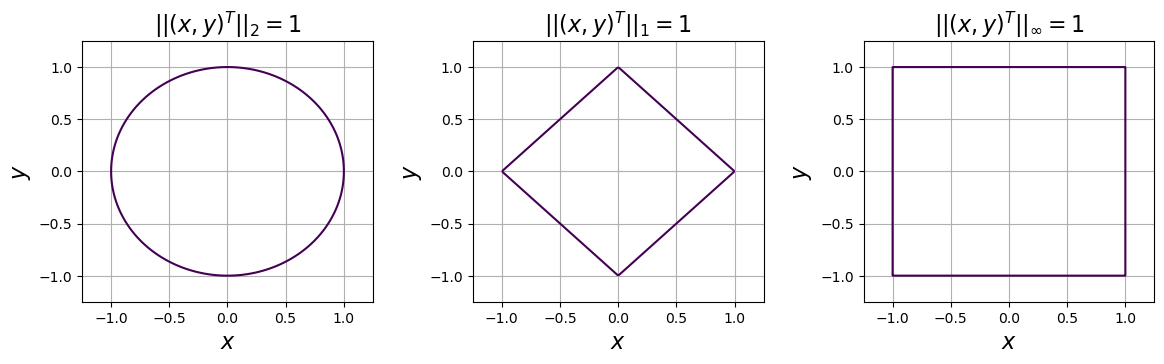

In [21]:
# define an x and y mesh spacing
x = np.linspace(-1.25, 1.25, 200)
y = x

# use meshgrid to expand these vectors to matrices
[X, Y] = np.meshgrid(x, y)

# initialise space to store the norm values over the (x,y) domain,
# i.e. these are matrices
two_norm = np.zeros_like(X)
one_norm = np.zeros_like(X)
inf_norm = np.zeros_like(X)

# loop over all points in our 2D space
for i in range(len(x)):
    for j in range(len(y)):
        # define the point as a vector of length 2
        op = np.array([X[i, j], Y[i, j]])  # the point meshgrid places at [i, j]
        # compute and store the norm values
        two_norm[i, j] = sl.norm(op, 2)
        one_norm[i, j] = sl.norm(op, 1)
        inf_norm[i, j] = sl.norm(op, np.inf)

# we can now plot the "unit circles" using a contour plot where we only plot the unit contour:
fig = plt.figure(figsize=(12, 4))

ax1 = fig.add_subplot(131)

ax1.contour(X, Y, two_norm, levels = [1])
ax1.set_xlabel('$x$', fontsize=16)
ax1.set_ylabel('$y$', fontsize=16)
ax1.set_title('$|| (x,y)^T ||_{2} = 1$', fontsize=16)
ax1.grid(True)

ax2 = fig.add_subplot(132)

ax2.contour(X, Y, one_norm, levels = [1])
ax2.set_xlabel('$x$', fontsize=16)
ax2.set_ylabel('$y$', fontsize=16)
ax2.set_title('$|| (x,y)^T ||_{1} = 1$', fontsize=16)
ax2.grid(True)

ax3 = fig.add_subplot(133)

ax3.contour(X, Y, inf_norm, levels = [1])
ax3.set_xlabel('$x$', fontsize=16)
ax3.set_ylabel('$y$', fontsize=16)
ax3.set_title(r'$|| (x,y)^T ||_{\infty} = 1$', fontsize=16)
ax3.grid(True)

plt.tight_layout(pad = 2.0)

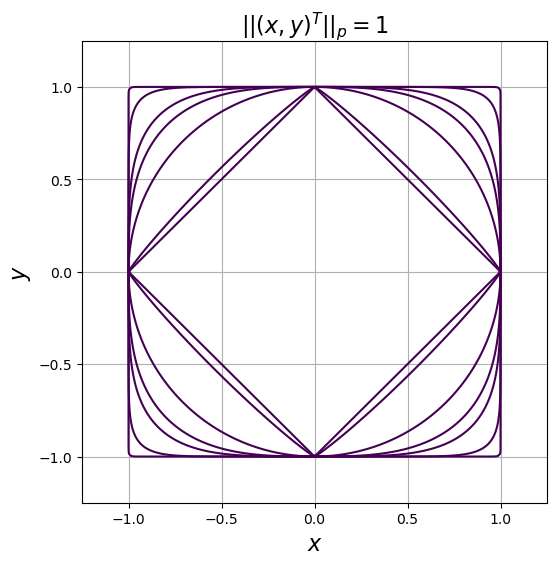

In [22]:
# define an x and y mesh spacing
x = np.linspace(-1.25, 1.25, 200)
y = x

# use meshgrid to expand these vectors to matrices
[X, Y] = np.meshgrid(x, y)

fig = plt.figure(figsize=(6, 6))
ax1 = fig.add_subplot(111)

def p_norm_fun(x, p=2):
    return (np.sum( np.abs(x)**p ))**(1/p)

for p in [1,1.1,2,3,4,10,100]:
    p_norm = np.zeros_like(X)
    for i in range(len(x)):
        for j in range(len(y)):
            # define the point as a vector of length 2
            op = np.array([X[i, j], Y[i, j]])  # the point meshgrid places at [i, j]
            # compute and store the norm values
            p_norm[i, j] = p_norm_fun(op, p)
    ax1.contour(X, Y, p_norm, levels = [1])

ax1.set_xlabel('$x$', fontsize=16)
ax1.set_ylabel('$y$', fontsize=16)
ax1.set_title('$|| (x,y)^T ||_{p} = 1$', fontsize=16)
ax1.grid(True)

So $p=1$ clearly recreates the one-norm - we can see this from the definition.

We see from the plots that larger and larger $p$ values get us closer to the max-norm result.

See the discussion here on robust implementation of the p norm <https://timvieira.github.io/blog/post/2014/11/10/numerically-stable-p-norms/>

<div class="optional">
    
## Impact of the norm used in linear best fit [\*]

Try updating the example from class so that the linear best fit line goes through the origin, i.e. you are optimising for the slope parameter only with each line going through the origin (the intercept is zero).

</div>

### Solution -  impact of the norm used in linear best fit 

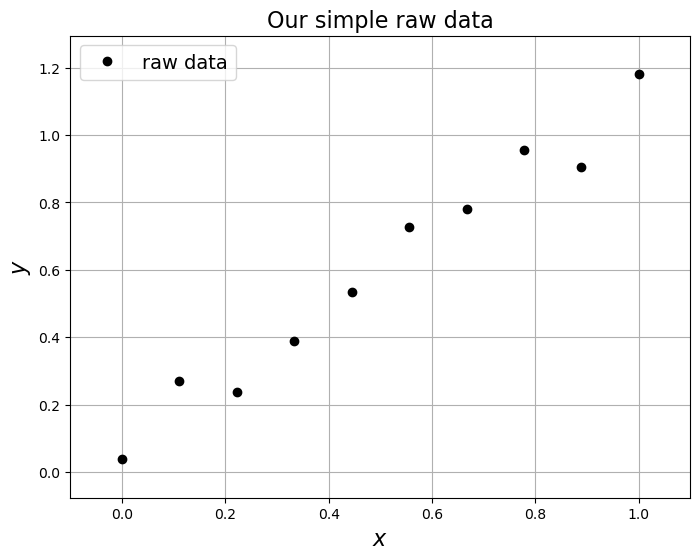

In [23]:
# Invent some raw data - we will use the notation (xi,yi) for the
# given data, where xi and yi are of length N+1 (N=len(xi)-1)
xi = np.linspace(0,1,10)
yi = xi +  0.2 * np.random.random((10,))

# We will want to overlay a plot of the raw data a few times below so 
# let's do this via a function that we can call repeatedly
# [Note that I've been a bit lazy in later lectures and really should
# do this sort of thing more often to make code easier to read - apologies]
def plot_raw_data(xi, yi, ax):
    """Plot x vs y on axes ax, 
    add axes labels and turn on grid

    Parameters
    ----------
    xi : array_like
        Array containing x data
    yi : array_like
        Array containing y data
    ax :  matplotlib axes, optional
        The axes to plot on
    """
    ax.plot(xi, yi, 'ko', label='raw data')
    ax.set_xlabel('$x$', fontsize=16)
    ax.set_ylabel('$y$', fontsize=16)
    ax.grid(True)


# set up figure
fig = plt.figure(figsize=(8, 6))
ax1 = fig.add_subplot(111)

# For clarity we are going to add a small margin to all the plots.
ax1.margins(0.1)

# plot the raw data
plot_raw_data(xi, yi, ax1)

# add a figure title
ax1.set_title('Our simple raw data', fontsize=16)

# Add a legend
ax1.legend(loc='best', fontsize=14);
# loc='best' means we let matplotlib decide the best place for the
# legend to go.  For other options see:
#  https://matplotlib.org/api/_as_gen/matplotlib.pyplot.legend.html

poly_coeffs:  [1.0733555761557783 0.0652630120894131]


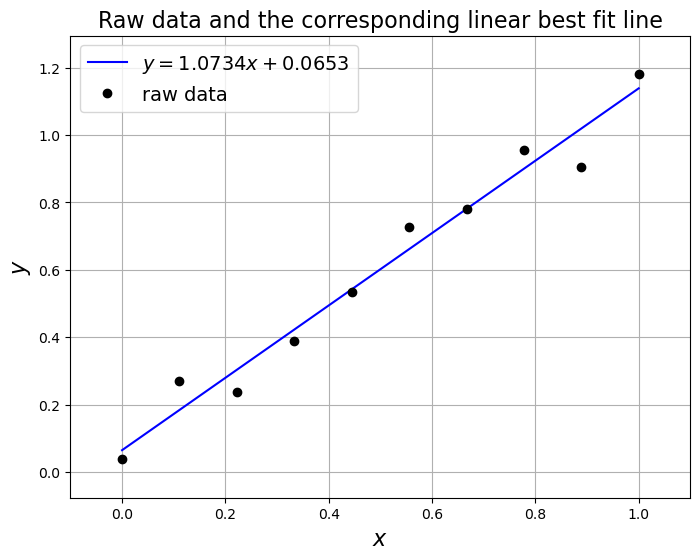

In [24]:
# Fit a polynomial of degree 1, i.e. a straight line, to our (xi, yi) data from above
degree = 1
poly_coeffs = np.polyfit(xi, yi, degree)
print('poly_coeffs: ',poly_coeffs)

# use poly1d to turn the coeffs into a function, p1, we can evaluate
p1 = np.poly1d(poly_coeffs)

# set up figure
fig = plt.figure(figsize=(8, 6))
ax1 = fig.add_subplot(111)
ax1.margins(0.1)

# Plot the linear fit - define 100 evenly spaced points (x) covering our
# x extent and plot our linear polynomial evaluated at these points (p1(x))
# of course 100 is overkill for this linear example
x = np.linspace(0., 1, 100)


ax1.plot(x, p1(x), 'b', label=r'$y = {0:.4f}x+{1:.4f}$'.format(poly_coeffs[0], poly_coeffs[1]))

# Overlay raw data
plot_raw_data(xi, yi, ax1)

# Add a legend
ax1.legend(loc='best', fontsize=14)

# add a figure title
ax1.set_title('Raw data and the corresponding linear best fit line', fontsize=16);

(As in the lecture, the one-norm and max-norm costs are not differentiable, so we use a derivative-free method, `method='Nelder-Mead'`, for them: `minimize`'s default gradient-based method stops early on these costs.)

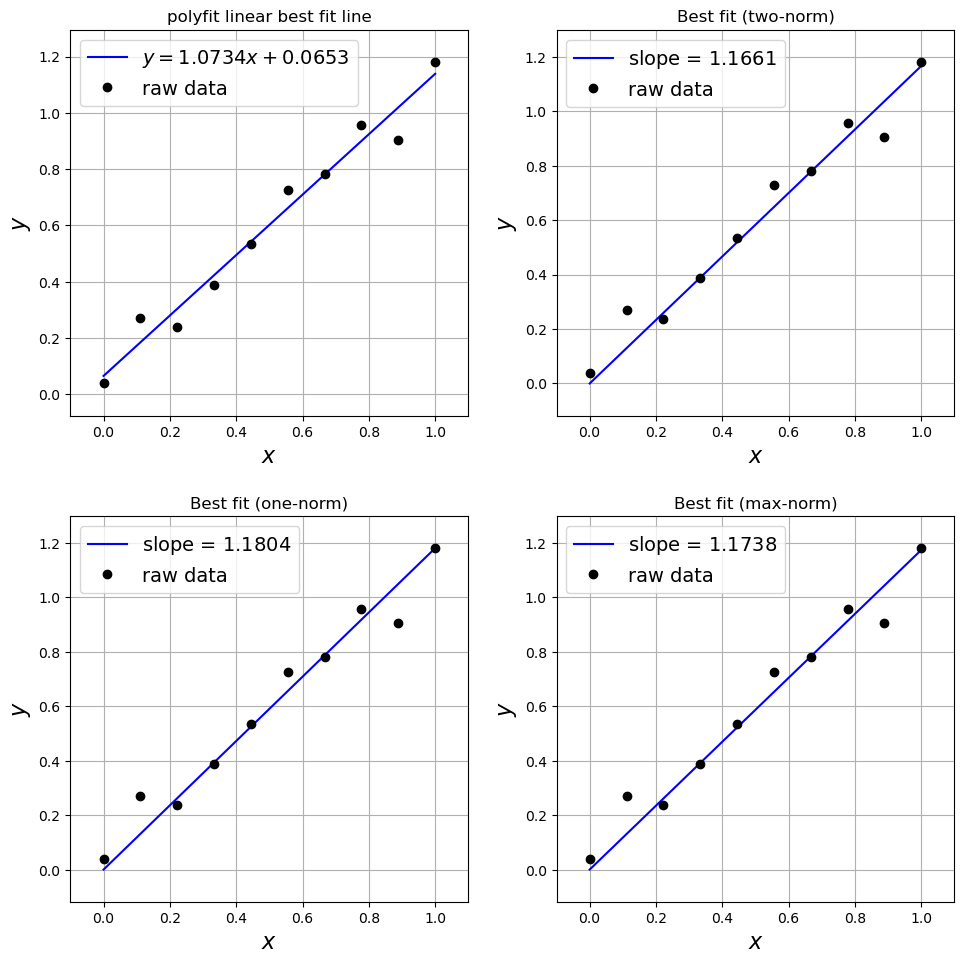

In [25]:
from scipy.optimize import minimize

### Set origin of line to (0,0)
def line_fit(x, line_slope):
    return line_slope*x + 0.

def cost_fun(line_slope, x, y, norm):
    """Cost function using two, one or max-norm

    Parameters
    ----------
    line_slope : float
        Slope of best fit line
    x : array_like
        Array containing x data
    y : array_like
        Array containing y data
    norm : string
        'two' for two-norm, 'one' for one-norm, 'max' for max-norm
    """
    if norm=='two':
        return sl.norm(y - line_fit(x, line_slope), 2)
    elif norm=='one':
        return sl.norm(y - line_fit(x, line_slope), 1)
    elif norm=='max':
        return sl.norm(y - line_fit(x, line_slope), np.inf)
    else:
        raise ValueError('check your norm string')

degree = 1
poly_coeffs = np.polyfit(xi, yi, degree)
p1 = np.poly1d(poly_coeffs)

# set up figure
fig = plt.figure(figsize=(10, 10))

# polyfit line
ax = fig.add_subplot(221)
ax.margins(0.1)
x = np.linspace(0., 1, 100)
ax.plot(x, p1(x), 'b', label=r'$y = {0:.4f}x+{1:.4f}$'.format(poly_coeffs[0], poly_coeffs[1]))
plot_raw_data(xi, yi, ax)
ax.legend(loc='best', fontsize=14)
ax.set_title('polyfit linear best fit line', fontsize=12)

# minimise two-norm cost function
x0 = poly_coeffs[0]
output = minimize(cost_fun, x0, args=(xi,yi,'two'))
ax = fig.add_subplot(222)
ax.margins(0.1)
x = np.linspace(0., 1, 100)
ax.plot(x, output.x * x, 'b', label=r'slope = ${0:.4f}$'.format(output.x[0]))
plot_raw_data(xi, yi, ax)
ax.legend(loc='best', fontsize=14)
ax.set_title('Best fit (two-norm)', fontsize=12)

# minimise one-norm cost function
x0 = poly_coeffs[0]
output = minimize(cost_fun, x0, args=(xi,yi,'one'), method='Nelder-Mead', options={'xatol': 1e-10, 'fatol': 1e-12, 'maxiter': 10000})
ax = fig.add_subplot(223)
ax.margins(0.1)
x = np.linspace(0., 1, 100)
ax.plot(x, output.x * x, 'b', label=r'slope = ${0:.4f}$'.format(output.x[0]))
plot_raw_data(xi, yi, ax)
ax.legend(loc='best', fontsize=14)
ax.set_title('Best fit (one-norm)', fontsize=12)

# minimise max-norm cost function
x0 = poly_coeffs[0]
output = minimize(cost_fun, x0, args=(xi,yi,'max'), method='Nelder-Mead', options={'xatol': 1e-10, 'fatol': 1e-12, 'maxiter': 10000})
ax = fig.add_subplot(224)
ax.margins(0.1)
x = np.linspace(0., 1, 100)
ax.plot(x, output.x * x, 'b', label=r'slope = ${0:.4f}$'.format(output.x[0]))
plot_raw_data(xi, yi, ax)
ax.legend(loc='best', fontsize=14)
ax.set_title('Best fit (max-norm)', fontsize=12)


plt.tight_layout(pad = 2.0)

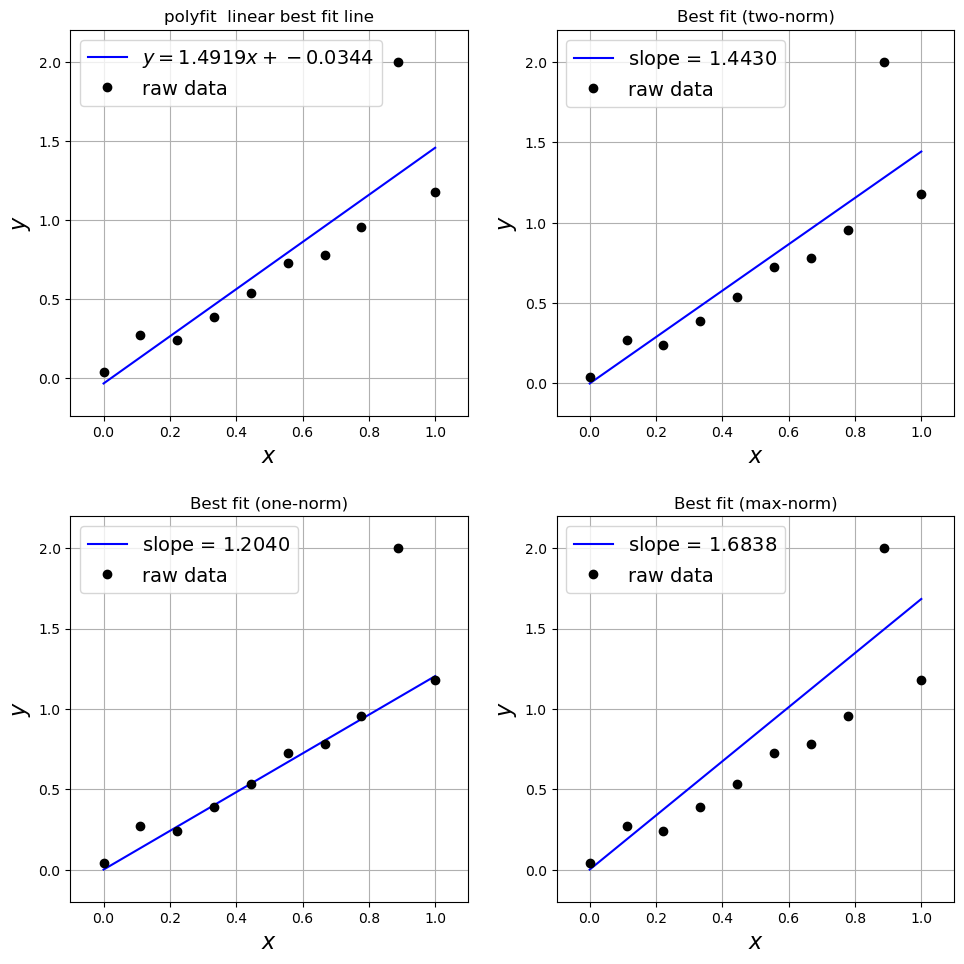

In [26]:
#perturb one of the entries

yi[8] = 2.

degree = 1
poly_coeffs = np.polyfit(xi, yi, degree)
p1 = np.poly1d(poly_coeffs)

# set up figure
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(221)
ax.margins(0.1)
x = np.linspace(0., 1, 100)
ax.plot(x, p1(x), 'b', label=r'$y = {0:.4f}x+{1:.4f}$'.format(poly_coeffs[0], poly_coeffs[1]))
plot_raw_data(xi, yi, ax)
ax.legend(loc='best', fontsize=14)
ax.set_title('polyfit  linear best fit line', fontsize=12)

# minimise two-norm cost function
x0 = poly_coeffs[0]
output = minimize(cost_fun, x0, args=(xi,yi,'two'))
ax = fig.add_subplot(222)
ax.margins(0.1)
x = np.linspace(0., 1, 100)
ax.plot(x, output.x * x, 'b', label=r'slope = ${0:.4f}$'.format(output.x[0]))
plot_raw_data(xi, yi, ax)
ax.legend(loc='best', fontsize=14)
ax.set_title('Best fit (two-norm)', fontsize=12)

# minimise one-norm cost function
x0 = poly_coeffs[0]
output = minimize(cost_fun, x0, args=(xi,yi,'one'), method='Nelder-Mead', options={'xatol': 1e-10, 'fatol': 1e-12, 'maxiter': 10000})
ax = fig.add_subplot(223)
ax.margins(0.1)
x = np.linspace(0., 1, 100)
ax.plot(x, output.x * x, 'b', label=r'slope = ${0:.4f}$'.format(output.x[0]))
plot_raw_data(xi, yi, ax)
ax.legend(loc='best', fontsize=14)
ax.set_title('Best fit (one-norm)', fontsize=12)

# minimise max-norm cost function
x0 = poly_coeffs[0]
output = minimize(cost_fun, x0, args=(xi,yi,'max'), method='Nelder-Mead', options={'xatol': 1e-10, 'fatol': 1e-12, 'maxiter': 10000})
ax = fig.add_subplot(224)
ax.margins(0.1)
x = np.linspace(0., 1, 100)
ax.plot(x, output.x * x, 'b', label=r'slope = ${0:.4f}$'.format(output.x[0]))
plot_raw_data(xi, yi, ax)
ax.legend(loc='best', fontsize=14)
ax.set_title('Best fit (max-norm)', fontsize=12)


plt.tight_layout(pad = 2.0)

## SymPy and the logistic ODE


In lecture 1 we considered the logistic ODE

$$\frac{dx}{dt} = \alpha x(1-x), \qquad x(0)=x_0$$

and derived the following solution

$$x(t) = \frac{x_0}{x_0 + (1-x_0)e^{-\alpha t}}$$

Use SymPy to derive the same solution symbolically

### Solution - SymPy and the logistic ODE


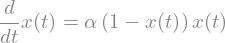

In [27]:
import sympy as sym
# print maths nicely:
sym.init_printing()
# define the 'symbols' that will be our variables/parameters
t, alpha, x0 = sym.symbols('t, alpha, x0')
# define a function - this will be the solution we're looking for
x = sym.Function('x')
# define this function's derivative with respect to t
dxdt = x(t).diff(t)
# define the ODE - see https://docs.sympy.org/latest/tutorial/gotchas.html#tutorial-gotchas-equals
logistic_expr = sym.Eq(dxdt, alpha*x(t)*(1-x(t))) 
# print it out to check it's correct
logistic_expr

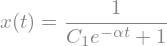

In [28]:
# solve the ODE
logistic_sol = sym.dsolve(logistic_expr, x(t))
logistic_sol

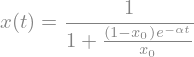

In [29]:
# above included a constant of integration C_1, 
# we can specify this in the solve so we don't need to work it out separately
logistic_sol = sym.dsolve(logistic_expr, x(t), ics={x(0):x0})
logistic_sol

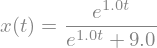

In [30]:
# substitute in our parameter values
logistic_sol_ic = sym.simplify(logistic_sol.subs({x0:0.1, alpha:1.0}))
logistic_sol_ic

In [31]:
# and turn it into a function we can evaluate
logistic_sol_fun = sym.lambdify(t, logistic_sol_ic.rhs)
print(logistic_sol_fun(1))

0.23196931668407395


In [32]:
def x_ex(t, x0, alpha):
    """Function to evaluate the exact solution to the logistic problem.

    Parameters
    ----------
    t : numpy.ndarray or float
        Times
    x0 : float
        Initial population, value from 0 to 1
    alpha : float
        Parameter

    Returns
    -------
    numpy.ndarray or float
        Function values for times given
    """
    return x0/(x0 + (1-x0)*np.exp(-alpha*t))

print(x_ex(1, 0.1, 1))

0.23196931668407392


## Round-off vs truncation errors

Given a function $f(x)$, a Taylor series analysis tells us that the following is a first-order approximation to its derivative:

$$f'(x) \approx \frac{f(x+\Delta x) - f(x)}{\Delta x} $$

Of course this is just the finite version of the mathematics you used to first learn about what a derivative is:

$$f'(x) = \lim_{\Delta x \rightarrow 0} \frac{f(x+\Delta x) - f(x)}{\Delta x} $$

Code up this approximation and plot the error as a function of $\Delta x$, and see what happens as we vary $\Delta x$ from very large to very small values (make sure you don't go to extreme with these as you might experience overflow!)

You could test with the function $f(x) = \exp(x)$ at $x=1$ say, but other examples should show similar results.

### Solution - round-off vs truncation errors

[2.7182818284590451e+00 1.7226102700415811e+00 6.1238724541642453e-01
 6.1238724541642453e-01 5.7275733103846260e-02 8.1502144974298307e-02
 5.7275733103846260e-02 2.2581263584310118e-02 5.2340288245420474e-03
 5.2340288245420474e-03 8.9722013460002970e-04 1.2711842103709792e-03
 8.9722013460002970e-04 1.8698203788547474e-04 8.4068505235901370e-05
 5.1456766324786685e-05 1.6305869455557342e-05 1.6305869455557342e-05
 6.3478948941764202e-07 6.3478948941764202e-07 3.6003752468261041e-06
 6.3478948941764202e-07 4.2400169464329451e-07 1.0539389760921836e-07
 1.0539389760921836e-07 2.6955000453909861e-08 3.9219448577654248e-08
 2.6955000453909861e-08 4.3498612711800888e-08 7.6585837227582942e-08
 1.4689618943464211e-07 2.9372074816791383e-07 5.8323396245896220e-07
 1.1679472580183869e-06 2.3353058975494889e-06 4.6700231766116929e-06
 9.3399747220779261e-06 1.8679974748803119e-05 3.7360136361019869e-05
 7.4720936183325648e-05 1.4944459974097768e-04 2.9890015625300137e-04
 5.9784413839780726e

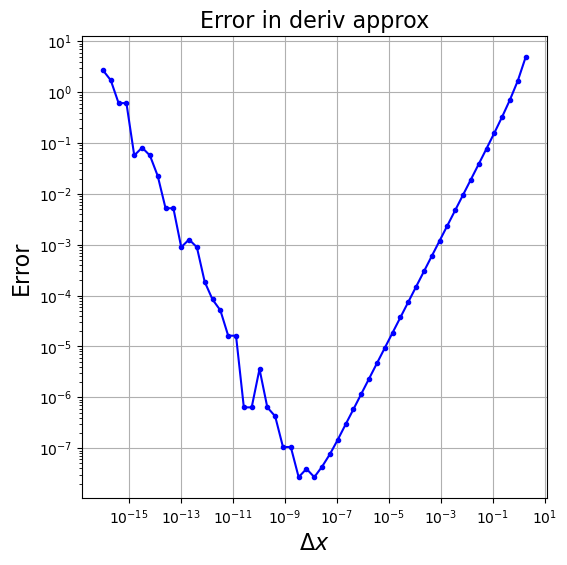

In [33]:
dx = np.array([1e-16 * 2**n for n in range(55)])
# approximate derivative at this x location
x = 1 *np.ones_like(dx)
# compute finite diff approximation to derivative, for all dx vals
dfdx = (np.exp(x + dx) - np.exp(x)) / dx
# compute the error
error = np.abs( dfdx - np.exp(x)*np.ones_like(dx) )
print(error)

fig = plt.figure(figsize=(6, 6))
ax1 = fig.add_subplot(111)
ax1.loglog(dx, error, 'b.-')
ax1.set_xlabel(r'$\Delta x$', fontsize=16)
ax1.set_ylabel('Error', fontsize=16)
ax1.set_title('Error in deriv approx', fontsize=16)
ax1.grid(True)

To the left we are falling foul of round-off errors, to the right truncation errors.

Something we can conclude from this is that round-off errors are somewhat random, while truncation errors seem to be better behaved, or follow some rule we might be able to figure out and hence do something to reduce - more on this in later modules.

[\*] We can make this quantitative. The truncation error of the formula is about $\frac{\Delta x}{2}|f''(x)|$ (the first Taylor-series term we dropped), so it falls like $\Delta x$ (slope 1 on the right of the plot). The numerator $f(x+\Delta x)-f(x)$ carries a round-off error of about $\epsilon|f(x)|$ ($\epsilon\approx 2.2\times10^{-16}$, machine epsilon), which dividing by $\Delta x$ turns into about $\epsilon|f(x)|/\Delta x$: this *grows* like $1/\Delta x$ as $\Delta x\to0$ (slope $-1$ on the left). The two balance at $\Delta x\sim\sqrt{\epsilon}\approx10^{-8}$, which is where the plot has its minimum, with an error of about $10^{-8}$: we can never get more than about half the available digits from this formula.

<div class="optional">
    
## Vandermonde matrices [*]

We will see in a later lecture how polynomial interpolation using a monomial basis involves the solution of a linear system with a so-called [Vandermonde matrix](https://en.wikipedia.org/wiki/Vandermonde_matrix).

A potential issue is that Vandermonde matrices are known to be ill-conditioned.

Assume that we are dealing with a square matrix, write some code to construct the Vandermonde matrix given a vector of $\alpha$ values. You can check your code against `np.vander`.

Investigate how the condition number of the matrix varies for a uniform mesh of data points in $x$ (i.e. `alpha = np.linspace(0, 1, n)`) as a function of the number of points in the mesh (`n`).

</div>

### Solution - Vandermonde matrices

Our vdm function agrees with numpy.vander: True
3 15.099657722502098
4 98.86773850722766
5 686.4349418185958
6 4924.37105661106
7 36061.16088021607
8 267816.70090775227
9 2009396.3800201367
10 15193229.677049411
11 115575244.51730081
12 883478686.2975326


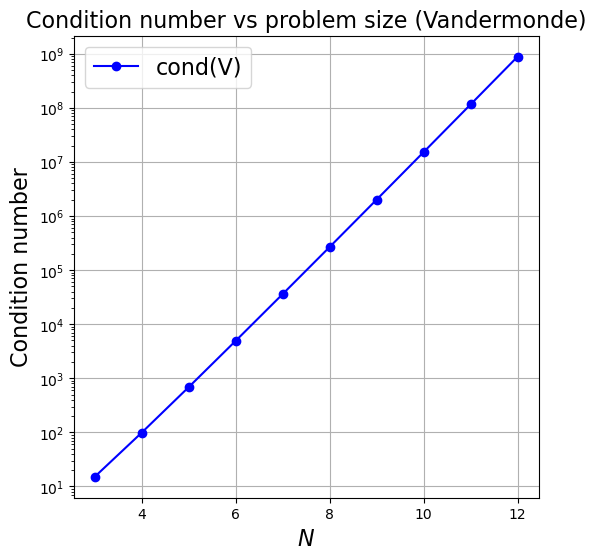

In [34]:
# compute a single row
def vdm_row(alpha, n):
    row = np.zeros(n)
    cur_alpha = 1
    for i in range(n):
        row[i] = cur_alpha
        cur_alpha *= alpha
    return row

# compute the matrix by calling the row function
def vdm(alpha_vec):
    n = alpha_vec.size
    A = np.zeros((n, n))
    for i in range(n):
        A[i, :] = vdm_row(alpha_vec[i], n)
    return A

# check our implementation against the in-built numpy function
x = np.linspace(0, 1, 10)
print('Our vdm function agrees with numpy.vander:', np.allclose(vdm(x), np.vander(x, increasing=True)))

# print and plot how condition number varies with problem size n
nns = 10
ns = np.linspace(3, 3+nns-1, nns, dtype=int)
condV = np.zeros(len(ns))
for i, n in enumerate(ns):
    x = np.linspace(0, 1, n)
    V = vdm(x)
    condV[i]=np.linalg.cond(V)
    print(n, condV[i])

# set up figure
fig = plt.figure(figsize=(6, 6))
ax1 = fig.add_subplot(111)

ax1.semilogy(ns, condV, 'bo-', label='cond(V)')
ax1.set_xlabel('$N$', fontsize=16)
ax1.set_ylabel('Condition number', fontsize=16)
ax1.set_title('Condition number vs problem size (Vandermonde)', fontsize=16)
ax1.legend(loc='best', fontsize=16)
ax1.grid(True)


<div class="optional">
    
## Hilbert matrix [*]

The *Hilbert matrix* is a classic example of an ill-conditioned (square) matrix:

$$
A = 
  \begin{pmatrix}
    1      & 1/2    & 1/3    & \cdots \\
    1/2    & 1/3    & 1/4    & \cdots \\
    1/3    & 1/4    & 1/5    & \cdots \\
    \vdots & \vdots & \vdots & \ddots  \\
\end{pmatrix}\,.
$$

Let's consider the linear system $A\boldsymbol{x}=\boldsymbol{b}$ where the RHS vector is defined as

$$ b_i = \sum_{j=1}^n a_{ij},\;\;\; \text{for}\;\;\;\; i=1,2,\ldots, n.$$


- Think about how you can write entry $a_{ij}$ for any $i$ and $j$ mathematically, and use this to write a function that generates the Hilbert matrix for a given $n$.


- Convince yourself that $ \boldsymbol{x} = \left[ 1, 1, \cdots 1\right]^T$ is the exact solution of the system.


- Write a function that returns $A$ and $b$ for a given $n$.


- For a range of $n$, compute the condition number of $A$, solve the linear system and compute the error between the NumPy/SciPy solution you obtain and the exact solution.  How does the error vary with $n$?

<br>

**Notes**

For this example we do not need to introduce any explicit perturbations in our problem in order to generate errors in our solution.

We can interpret the exact mathematical problem as written down above as the unperturbed case with the unperturbed exact solution being $ \boldsymbol{x} = \left[ 1, 1, \cdots 1\right]^T$.

Floating point errors will mean that every case we consider numerically will be perturbed slightly - both the entries of $A$ and $\boldsymbol{b}$ won't be exactly as they should be. With finite precision arithmetic our calculations can only be as accurate as [*machine epsilon*](https://en.wikipedia.org/wiki/Machine_epsilon) which assuming double precision is given by

```Python
print('machine epsilon = ', np.finfo(float).eps)
machine epsilon =  2.220446049250313e-16
```
The relation 

$$ \text{relative error of output}  \sim  \text{condition number} \times  \text{relative error of input} $$

therefore gives us an upper bound on how accurate we can expect our solution to be:

$$ \text{relative error of output}  \sim  \text{condition number} \times  \text{machine epsilon}. $$

Add this relation to your relative error plot and check it indeed provides an upper bound, which grows with $n$, and that our relative error is close to this value and grows in tandem with it as $n$ increases.

This emphasises the point that for ill-conditioned problems large errors can be expected even if only floating point errors are present.
    
</div>

### Solution - Hilbert matrix

machine epsilon =  2.220446049250313e-16


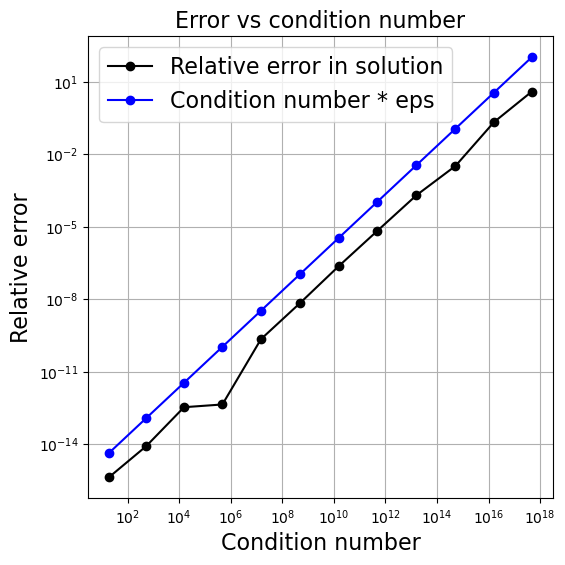

In [35]:
def hilbert(n):
    """Function to construct Hilbert matrix and RHS vector b.

    Parameters
    ----------
    n : int
        Size of the problem

    Returns
    -------
    tuple of ndarray
        Tuple containing Hilbert matrix A and RHS vector B
    """
    A = np.zeros((n, n))
    b = np.zeros(n)
    for i in range(n):
        for j in range(n):
            A[i, j] = 1./(i+j+1)
        b[i] = np.sum(A[i, :])
    return A, b

# set up n values and compute corresponding condition numbers and errors
n_max = 14
ns = range(2, n_max)
conds = np.zeros_like(ns, dtype=float)
errors = np.zeros_like(ns, dtype=float)
for i, n in enumerate(ns):
    A, b = hilbert(n)
    x = np.linalg.solve(A, b)
    x_exact = np.ones(n)
    errors[i] = sl.norm(x - x_exact,2) / sl.norm(x_exact,2) 
    conds[i] = np.linalg.cond(A)

print('machine epsilon = ', np.finfo(float).eps)

# set up figure
fig = plt.figure(figsize=(6, 6))
ax1 = fig.add_subplot(111)

ax1.loglog(conds, errors, 'ko-', label='Relative error in solution')
ax1.loglog(conds, conds * np.finfo(float).eps , 'bo-', label='Condition number * eps')
ax1.set_xlabel('Condition number', fontsize=16)
ax1.set_ylabel('Relative error', fontsize=16)
ax1.set_title('Error vs condition number', fontsize=16)
ax1.legend(loc='best', fontsize=16)
ax1.grid(True)

<div class="advanced">
    
## Ill-conditioned matrices and the solution of corresponding linear systems [\*\*]

Consider the problem from the lecture

$$
\left(
  \begin{array}{cc}
    2 & 1 \\
    2 & 1 + \epsilon  \\
  \end{array}
\right)\left(
  \begin{array}{c}
    x \\
    y \\
  \end{array}
\right) = \left(
  \begin{array}{c}
    3 \\
    0 \\
  \end{array}
\right)
$$

and let's consider the case where $\epsilon = 0.1$.

Consider the two extreme points we computed from class that corresponded to the magenta and black dots in our plots

```Python
A = np.array([[2.,1.],[2.,1. + 0.1]])

# these are the points we computed from class
origin_p = np.array([2.235621,2.282122])
origin_p2 = np.array([-0.044721,0.04381])
```

construct a small (I used a perturbation size of magnitude 0.01) circle of points around each of these - consider these as perturbed RHS $\boldsymbol{b}$ values. 

Compute and plot the corresponding shape you get for the set of perturbed solutions $\boldsymbol{x}$.

Compute the maximum value of the ratio of the relative perturbation in $x$ to the relative perturbation in $b$:

$$\frac{  {\|\delta \boldsymbol{x}\|} / {\|\boldsymbol{x}\|}   }{  {\|\delta \boldsymbol{b}\|} / {\|\boldsymbol{b}\|}    } $$

for each case and convince yourself that for both this quantity is bounded by the condition number as the theory implies.
    
</div>

### Solution - ill-conditioned matrices and the solution of corresponding linear systems 


1.0000067973524411 51.03034644405538
0.01959629401546271 0.9999988752838117
51.0304038391865


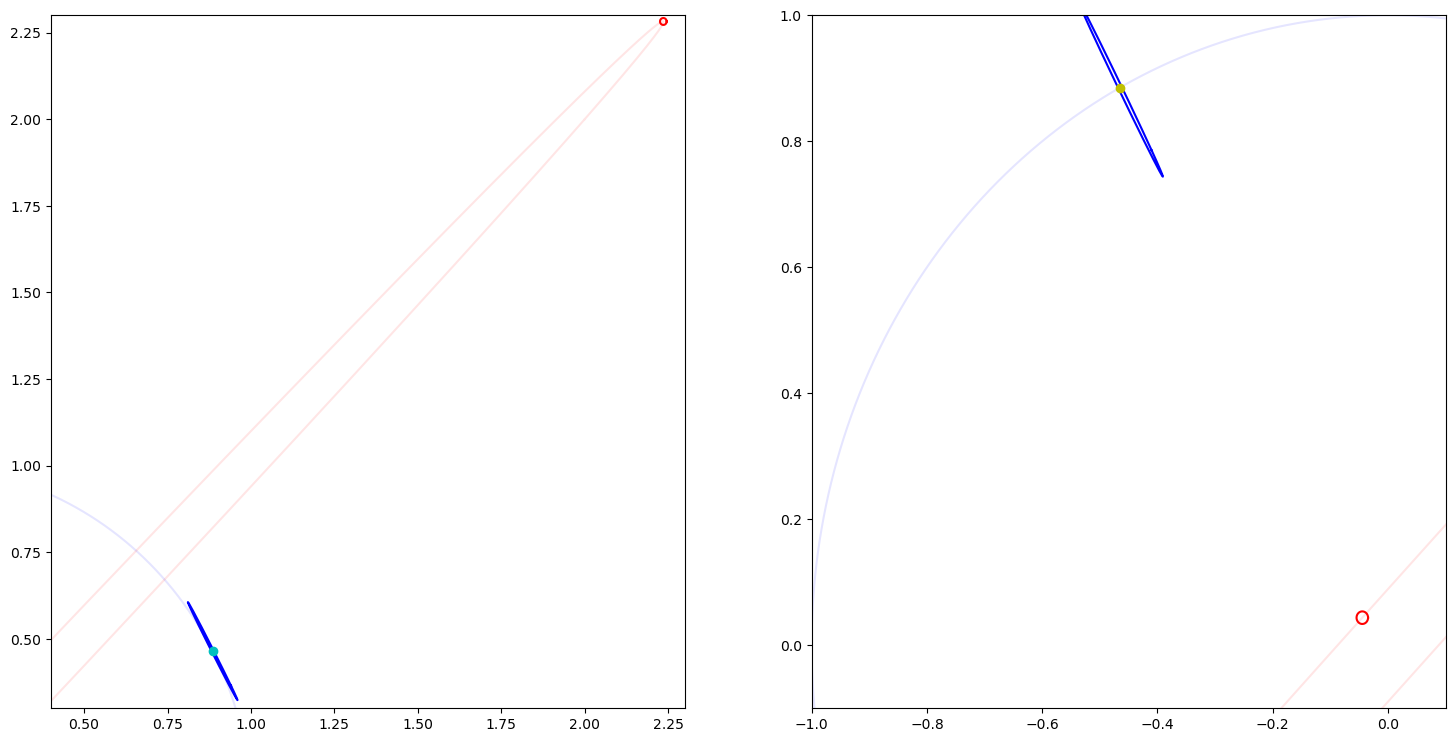

In [36]:
A = np.array([[2.,1.],[2.,1. + 0.1]])

# these are the points we computed from class
origin_p = np.array([2.235621,2.282122])
origin_p2 = np.array([-0.044721,0.04381])

fig = plt.figure(figsize=(18, 9))
ax1 = fig.add_subplot(121)

# construct points on a circle parametrically
theta = np.linspace(0,2*np.pi,1000) # runs from 0 to 2*pi, so the curve closes
# radius of perturbed circle
r = 0.01
# A 2xn array of points around point
points = np.vstack( (r*np.cos(theta) + origin_p[0], r*np.sin(theta) + origin_p[1]) )

# plot the original circle and ellipse to remind us where this point lies
circle = np.vstack( (np.cos(theta), np.sin(theta)) )
ax1.plot(circle[0,:], circle[1,:], 'b', alpha=0.1)
circle_ = A@circle
ax1.plot(circle_[0,:], circle_[1,:], 'r', alpha=0.1)

# plot the circle around our point
ax1.plot(points[0,:], points[1,:], 'r')

pointsp = sl.inv(A)@points

# plot the transformed circle
ax1.plot(pointsp[0,:], pointsp[1,:], 'b')

origin_x = sl.inv(A)@origin_p
ax1.plot(origin_x[0], origin_x[1], 'co', lw=4, zorder=30)

rel_x_over_rel_b = np.zeros(np.shape(pointsp)[1])
for i in range(np.shape(pointsp)[1]):
    rel_x_over_rel_b[i] = ( ( sl.norm( pointsp[:,i] - origin_x, 2) / sl.norm( origin_x, 2)) /
                             (sl.norm( points[:,i] - origin_p, 2) / sl.norm( origin_p, 2)) ) 
print(np.min(rel_x_over_rel_b), np.max(rel_x_over_rel_b))

############  Consider a second location
ax2 = fig.add_subplot(122)

# construct points on a circle parametrically
theta = np.linspace(0,2*np.pi,1000) # runs from 0 to 2*pi, so the curve closes
# radius of circle
r = 0.01
# A 2xn array of points around point 2
points = np.vstack( (r*np.cos(theta) + origin_p2[0], r*np.sin(theta) + origin_p2[1]) )

# plot the original circle and ellipse to remind us where this point lies
circle = np.vstack( (np.cos(theta), np.sin(theta)) )
ax2.plot(circle[0,:], circle[1,:], 'b', alpha=0.1)
circle_ = A@circle
ax2.plot(circle_[0,:], circle_[1,:], 'r', alpha=0.1)

# plot the circle around our point
ax2.plot(points[0,:], points[1,:], 'r')

# corresponding x values
pointsp = sl.inv(A)@points

# plot the transformed circle
ax2.plot(pointsp[0,:], pointsp[1,:], 'b')

origin_x2 = sl.inv(A)@origin_p2
ax2.plot(origin_x2[0], origin_x2[1], 'yo', lw=4, zorder=30)

ax2.set_xlim(-1,0.1)
ax2.set_ylim(-0.1,1)

rel_x_over_rel_b = np.zeros(np.shape(pointsp)[1])
for i in range(np.shape(pointsp)[1]):
    rel_x_over_rel_b[i] = ( ( sl.norm( pointsp[:,i] - origin_x2, 2) / sl.norm( origin_x2, 2)) / 
                             (sl.norm( points[:,i] - origin_p2, 2) / sl.norm( origin_p2, 2)) )
print(np.min(rel_x_over_rel_b), np.max(rel_x_over_rel_b))
print(np.linalg.cond(A))

ax1.set_xlim(0.4,2.3)
ax1.set_ylim(0.3,2.3)

On the left, the relative perturbations to $\boldsymbol{b}$ are *relatively* small as our starting $\boldsymbol{b}$ is far from the origin, the corresponding $\boldsymbol{x}$ solution values are close to the origin and hence relatively speaking the perturbed distances from the cyan blob are quite large. This means the ratio of these relative measures is large and very close to but still bounded by the condition number.

On the right the situation is reversed - the perturbations to $\boldsymbol{b}$ are *relatively* large as our starting $\boldsymbol{b}$ is closer to the origin, while the resulting $\boldsymbol{x}$ values are farther away. Hence the ratio of the relative measures in this case is smaller.  

Since the matrix is fairly ill-conditioned in absolute terms we see quite a large *absolute* difference in both cases.